# Predicting March Madness
 Background: We are tasked with predicting the outcome of the 2025 NCAA Men's Basketball tournament. The tournament is historically hard to predict as the tournament is filled with upsets, cinderalla runs, and miracle shots.

 Personal Background: I just want to preface that I am a college basketball fan; it's my favorite sport. With that being said, my approach to building this model may be affected due to my preconceived notions about teams, coaches, players, "what wins in March", etc.

Overview: We predicted win probabilities in the NCAA Men's Basketball tournament using logistic regression with historical seeding win probabilities and [KenPom](https://kenpom.com/) power rankings.

Data source: I got all of my data thanks to this [competition](https://www.kaggle.com/competitions/march-machine-learning-mania-2025/data) on Kaggle (much of this notebook was adapted from my submission).

Credit:

Notebook that turns seed into win probabilities: [Nick M](https://www.kaggle.com/code/menanick/simple-predictions-seeds-probability/notebook)

Notebook that runs simulations and visualizes results: [Ryan Armstrong](https://www.kaggle.com/code/rsa013/march-madness-simulation-example/notebook)




## Import libraries

In [26]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.preprocessing import MinMaxScaler
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [2]:
from google.colab import drive # mount drive
drive.mount('/content/drive')
import IPython.display
%cd '/content/drive/MyDrive/march_madness'

Mounted at /content/drive
/content/drive/MyDrive/march_madness


## Data preprocessing

In [3]:
m_seed = pd.read_csv('MNCAATourneySeeds.csv') # list of seeds
m_tourney_results = pd.read_csv('MNCAATourneyCompactResults.csv') # results of tourneys
m_massey = pd.read_csv('MMasseyOrdinals.csv') # massey rankings
m_massey_2025 = pd.read_csv('MMasseyOrdinals_2025_133_56S.csv') # massey rankings 2025, day 133

In [4]:
m_seed.head()

,Season,Seed,TeamID
0,1985,W01,1207
1,1985,W02,1210
2,1985,W03,1228
3,1985,W04,1260
4,1985,W05,1374


In [5]:
m_tourney_results.head()

,Season,DayNum,WTeamID,WScore,LTeamID,LScore,WLoc,NumOT
0,1985,136,1116,63,1234,54,N,0
1,1985,136,1120,59,1345,58,N,0
2,1985,136,1207,68,1250,43,N,0
3,1985,136,1229,58,1425,55,N,0
4,1985,136,1242,49,1325,38,N,0


In [6]:
m_massey.head()

,Season,RankingDayNum,SystemName,TeamID,OrdinalRank
0,2003,35,SEL,1102,159
1,2003,35,SEL,1103,229
2,2003,35,SEL,1104,12
3,2003,35,SEL,1105,314
4,2003,35,SEL,1106,260


In [7]:
m_massey_2025.head()

,Season,RankingDayNum,SystemName,TeamID,OrdinalRank
0,2025,133,7OT,1101,213
1,2025,133,7OT,1102,280
2,2025,133,7OT,1103,57
3,2025,133,7OT,1104,3
4,2025,133,7OT,1105,341


In [8]:
m_massey_2025.head()

,Season,RankingDayNum,SystemName,TeamID,OrdinalRank
0,2025,133,7OT,1101,213
1,2025,133,7OT,1102,280
2,2025,133,7OT,1103,57
3,2025,133,7OT,1104,3
4,2025,133,7OT,1105,341


In [9]:
m_seed['SeedNum'] = m_seed['Seed'].str[1:3].astype(int)
m_seed = m_seed[m_seed['Season'] >= 2003]
m_seed.head()

,Season,Seed,TeamID,SeedNum
1154,2003,W01,1328,1
1155,2003,W02,1448,2
1156,2003,W03,1393,3
1157,2003,W04,1257,4
1158,2003,W05,1280,5


Limited dataset to 2003 onward since that's when KenPom started. Note that the KenPom formula has changed over time as well.

In [10]:
m_massey_2025 = m_massey_2025[m_massey_2025['SystemName'] == 'POM']
m_massey = m_massey[(m_massey['RankingDayNum'] == 133) & (m_massey['SystemName'] == 'POM')]
m_massey = pd.concat([m_massey, m_massey_2025], axis = 0)
m_massey.tail()

,Season,RankingDayNum,SystemName,TeamID,OrdinalRank
14213,2025,133,POM,1476,322
14214,2025,133,POM,1477,330
14215,2025,133,POM,1478,354
14216,2025,133,POM,1479,342
14217,2025,133,POM,1480,349


I decided to use KenPom because from what I have gathered, it seems to be the gold standard in rating college basketball teams.

In [11]:
merged = m_seed.merge(m_massey, on = ['Season', 'TeamID'], how = 'inner')
merged = merged.drop_duplicates(subset=['Season', 'Seed', 'TeamID'])
merged.head()

,Season,Seed,TeamID,SeedNum,RankingDayNum,SystemName,OrdinalRank
0,2003,W01,1328,1,133,POM,9
1,2003,W02,1448,2,133,POM,12
2,2003,W03,1393,3,133,POM,15
3,2003,W04,1257,4,133,POM,14
4,2003,W05,1280,5,133,POM,11


### Some utility functions:

In [12]:
# I use these functions here to create a format that is equivalent to our final submission
def add_id(df):
    df['LowTeamID'] = df[['WTeamID', 'LTeamID']].min(axis=1)
    df['HighTeamID'] = df[['WTeamID', 'LTeamID']].max(axis=1)
    df['ID'] = df['Season'].astype('str') + '_' + df['LowTeamID'].astype('str') + "_" + df['HighTeamID'].astype('str')
    df.drop(['LowTeamID', 'HighTeamID'], axis=1, inplace=True)
    return df

def id_to_teams(df):
    df['LowTeamID'] = df['ID'].str.split('_', expand=True)[1].astype('int')
    df['HighTeamID'] = df['ID'].str.split('_', expand=True)[2].astype('int')
    return df

def prep_tourney(df):
    df = add_id(df)
    df = id_to_teams(df)
    df['Actual'] = np.where(df['WTeamID'] == df['LowTeamID'], 1, 0)
    return df[['ID', 'Season', 'LowTeamID', 'HighTeamID', 'Actual']]

prep_tourney(m_tourney_results).sample(5) # sampling to get an idea of full dataframe

,ID,Season,LowTeamID,HighTeamID,Actual
1189,2003_1268_1277,2003,1268,1277,0
525,1993_1174_1257,1993,1174,1257,0
532,1993_1338_1428,1993,1338,1428,0
789,1997_1143_1437,1997,1143,1437,1
792,1997_1234_1246,1997,1234,1246,0


In [13]:
# Here we add the seeds and rankings and calculate the difference between the two teams
tourney_df = (
    prep_tourney(m_tourney_results)
    .merge(merged[['Season', 'TeamID','SeedNum', 'OrdinalRank']], left_on=['Season', 'LowTeamID'], right_on=['Season', 'TeamID'])
    .merge(merged[['Season', 'TeamID','SeedNum', 'OrdinalRank']], left_on=['Season', 'HighTeamID'], right_on=['Season', 'TeamID'])
    .drop(['TeamID_x', 'TeamID_y'], axis=1)
    .assign(SeedDiff = lambda x: x['SeedNum_x'] - x['SeedNum_y'])
    .assign(RankDiff = lambda x: x['OrdinalRank_x'] - x['OrdinalRank_y'])
)
tourney_df.head()

,ID,Season,LowTeamID,HighTeamID,Actual,SeedNum_x,OrdinalRank_x,SeedNum_y,OrdinalRank_y,SeedDiff,RankDiff
0,2003_1411_1421,2003,1411,1421,0,16,268,16,273,0,-5
1,2003_1112_1436,2003,1112,1436,1,1,3,16,144,-15,-141
2,2003_1113_1272,2003,1113,1272,1,10,32,7,20,3,12
3,2003_1141_1166,2003,1141,1166,1,11,50,6,27,5,23
4,2003_1143_1301,2003,1143,1301,1,8,40,9,48,-1,-8


## Sample splitting

Our training data is from 2003 to 2019. Our testing data is from 2021 to 2024. Note: 2020 tournament was cancelled due to COVID.

In [14]:
split_year = 2020
train = tourney_df[tourney_df['Season'] < split_year].copy()
test = tourney_df[tourney_df['Season'] >= split_year].copy()

X_train = train[['SeedDiff', 'RankDiff']]
y_train = train['Actual']

X_test = test[['SeedDiff', 'RankDiff']]
y_test = test['Actual']

X_train.head()

,SeedDiff,RankDiff
0,0,-5
1,-15,-141
2,3,12
3,5,23
4,-1,-8


### Scale features

In [15]:
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Implement logistic regression model

In [16]:
# Logistic Regression
logit_model = LogisticRegression()
logit_model.fit(X_train, y_train)
y_pred_train = logit_model.predict_proba(X_train)[:, 1]
y_pred_test = logit_model.predict_proba(X_test)[:, 1]

brier_train = brier_score_loss(y_train, y_pred_train)
brier_test = brier_score_loss(y_test, y_pred_test)
print(f" Train Brier Score: {brier_train}")
print(f" Test Brier Score: {brier_test}")

 Train Brier Score: 0.18671694789769838
 Test Brier Score: 0.21128228004935617


Overall, Brier score is okay. Guessing 0.5 for each game gets you a Brier score of 0.25, so it's slightly better than that.

## Feature Importance

In [17]:
feature_importance = np.abs(logit_model.coef_[0])  # absolute value of coefficients
feature_names = ['SeedDiff', 'RankDiff']
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})
print(importance_df)

    Feature  Importance
0  SeedDiff    3.542887
1  RankDiff    3.235104


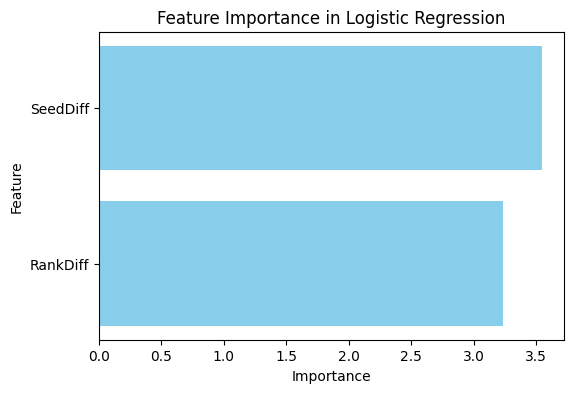

In [18]:
plt.figure(figsize=(6, 4))
plt.barh(importance_df["Feature"], importance_df["Importance"], color='skyblue')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in Logistic Regression")
plt.gca().invert_yaxis()  # Most important feature on top
plt.show()

Both features are important. Difference in seeding is slightly more important than difference in KenPom ranking.

## Model simulation


The follwing was used to simulate our model and visualize our results.

In [19]:
from google.colab import files
uploaded = files.upload() # importing script used to simulate submission file

Saving march_madness_simulator.py to march_madness_simulator (1).py


In [20]:
os.environ["COMPETITION_DATA_PATH"] = "/content/drive/MyDrive/march_madness"
from march_madness_simulator import start_tournament
from march_madness_simulator import simulate_n_tournaments

In [21]:
submission = pd.read_csv("submission2.csv")

Our final submission based on the model we used above.

In [22]:
# initialize the Tournament class
tournament = start_tournament(season=2025, mw="M", submission=submission,)

In [23]:
summary = simulate_n_tournaments(tournament, 1000)
summary

,Play-in Games,First Round,Round of 32,Sweet 16,Elite 8,Final 4,Championship
TeamID,,,,,,,
Florida (1196),0.000,0.938,0.711,0.459,0.280,0.176,0.110
Duke (1181),0.000,0.964,0.712,0.487,0.292,0.161,0.091
Houston (1222),0.000,0.963,0.703,0.476,0.279,0.150,0.074
Tennessee (1397),0.000,0.915,0.638,0.375,0.226,0.133,0.072
Michigan St (1277),0.000,0.902,0.626,0.408,0.234,0.124,0.071
...,...,...,...,...,...,...,...
SIUE (1188),0.000,0.037,0.007,0.000,0.000,0.000,0.000
Mt St Mary's (1291),0.499,0.022,0.003,0.000,0.000,0.000,0.000
Alabama St (1106),0.542,0.022,0.002,0.000,0.000,0.000,0.000


Aggregation of simulating our model 1,000 times.

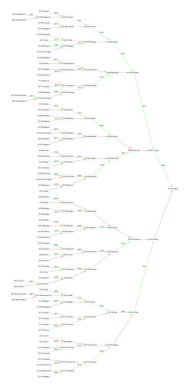

In [31]:
image = mpimg.imread('tournament_graph.jpg')
plt.imshow(image)
plt.axis('off')
plt.show()

This is the bracket labelled 3b759 I submitted based off a simulation of our model.

## Reflection

A basic logistic regression model performs okay. Using seeding and power rankings tends to favor the higher seeded which isn't always the case in betting markets, for example. The model is unable to capture much of the complexities of March Madness. Another drawback is the model uses KenPom power ranking as a feature which could better be served by using KenPom net rating, which does a better job of representing the difference between ranking spots.

Our model is doing pretty well right now since it's a fairly "chalk" year, meaning the top seeded teams have won at a pretty high rate and at the time of writing, has achieved a Brier score of 0.12618.

In the future, I hope to build more of a ratings / ELO based model that power rates teams and accounts for the complexities between seed lines and ranking spots. I hope to explore features like home court advantage, blue blood bias, and quantifying coaching effectiveness in the future.